# Brazilian Hydric Forecast

## Objective
The objective of this notebook is to analyze and forecast Brazilian hydric data.
Forecast Brazilian hydric data using DuckDB, Polars and AutoML for this task.

In [1]:
import duckdb
import os
from dotenv import load_dotenv

load_dotenv()

url = os.getenv("HIDRIC_URL")
display(url)

'https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/dados_hidrologicos_di/DADOS_HIDROLOGICOS_RES_2026.parquet'

In [2]:
import requests

api = "https://dados.ons.org.br/api/3/action/package_show"
params = {"id": "dados-hidrologicos-res"}

data = requests.get(api, params=params).json()

resources = data["result"]["resources"]

urls = [
    resource["url"] 

    # iterate over all resources
    for resource in resources 

    # Filter only PARQUET resources
    if resource["format"].upper() == "PARQUET"
]

display(urls[:5])

['https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/dados_hidrologicos_di/DADOS_HIDROLOGICOS_RES_2000.parquet',
 'https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/dados_hidrologicos_di/DADOS_HIDROLOGICOS_RES_2001.parquet',
 'https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/dados_hidrologicos_di/DADOS_HIDROLOGICOS_RES_2002.parquet',
 'https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/dados_hidrologicos_di/DADOS_HIDROLOGICOS_RES_2003.parquet',
 'https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/dados_hidrologicos_di/DADOS_HIDROLOGICOS_RES_2004.parquet']

In [3]:
formatted_urls = ", ".join([f"'{url}'" for url in urls])
display(formatted_urls)

"'https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/dados_hidrologicos_di/DADOS_HIDROLOGICOS_RES_2000.parquet', 'https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/dados_hidrologicos_di/DADOS_HIDROLOGICOS_RES_2001.parquet', 'https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/dados_hidrologicos_di/DADOS_HIDROLOGICOS_RES_2002.parquet', 'https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/dados_hidrologicos_di/DADOS_HIDROLOGICOS_RES_2003.parquet', 'https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/dados_hidrologicos_di/DADOS_HIDROLOGICOS_RES_2004.parquet', 'https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/dados_hidrologicos_di/DADOS_HIDROLOGICOS_RES_2005.parquet', 'https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/dados_hidrologicos_di/DADOS_HIDROLOGICOS_RES_2006.parquet', 'https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/dados_hidrologicos_di/DADOS_HIDROLOGICOS_RES_2007.parquet', 'https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/dados_hidrologi

In [ ]:
con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")

In [23]:

con.execute("SET allow_asterisks_in_http_paths = true")

url = (
    "https://portal1.snirh.gov.br/arcgis/rest/services/"
    "SPR/Armazena_Reservatorio_UGRH/FeatureServer/0/query"
    "?where=1%3D1&outFields=*&returnGeometry=false&f=json"
)

result = con.execute("""
    SELECT *
    FROM read_json_auto(?)
""", [url]).df()

In [26]:
print(result.to_markdown())

|    | objectIdFieldName   | globalIdFieldName   | geometryType        | spatialReference                   | fields                                                                                          | features                                                                                                                                                                                               |
|---:|:--------------------|:--------------------|:--------------------|:-----------------------------------|:------------------------------------------------------------------------------------------------|:-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
|  0 | OBJECTID            |                     | esriGeometryPolygon | {'wkid': 4674, 'latestWkid': 4674} | [{'name': 'CAPESTHM3', 'alias': 'CAPESTHM3', 'type': 'esriFieldTypeDoubl

In [31]:

url = (
    "https://portal1.snirh.gov.br/arcgis/rest/services/"
    "SPR/Armazena_Reservatorio_UGRH/FeatureServer/0/query"
    "?where=1%3D1&outFields=*&returnGeometry=false&f=json"
)

df = con.execute("""
    SELECT
        feature.attributes.OBJECTID AS object_id,
        feature.attributes.ID AS id,
        feature.attributes.CDUGF AS codigo_ugrh,
        feature.attributes.NMUGF AS unidade_gestao,
        feature.attributes.CAPESTHM3 AS capacidade_estimada_hm3,
        feature.attributes.QTRESERV AS quantidade_reservatorios
    FROM (
        SELECT unnest(features) AS feature
        FROM read_json_auto(?)
    )
    ORDER BY codigo_ugrh
""", [url]).df()

print(df)

    object_id  id  codigo_ugrh  \
0           1  20            1   
1           2  41            2   
2           3  48            3   
3           4  17            4   
4           5  10            5   
..        ...  ..          ...   
59         60   1           60   
60         61  61           61   
61         62  62           62   
62         63  63           63   
63         64  50           64   

                                      unidade_gestao  capacidade_estimada_hm3  \
0                                   Lagoa Mirim/Chuí               552.712549   
1                                            Uruguai             23525.460690   
2                                          Mampituba                22.386123   
3                                             Iguaçu             21451.169610   
4             Bacias Interestaduais do Litoral SC/PR                 0.599845   
..                                               ...                      ...   
59                 Bacia

In [32]:
df

,object_id,id,codigo_ugrh,unidade_gestao,capacidade_estimada_hm3,quantidade_reservatorios
0,1,20,1,Lagoa Mirim/Chuí,552.712549,836
1,2,41,2,Uruguai,23525.460690,21718
2,3,48,3,Mampituba,22.386123,115
3,4,17,4,Iguaçu,21451.169610,5147
4,5,10,5,Bacias Interestaduais do Litoral SC/PR,0.599845,21
...,...,...,...,...,...,...
59,60,1,60,Bacias Litorâneas Estaduais do CE,21170.925960,6508
60,61,61,61,Bacias Litorâneas Estaduais do MA,1996.318311,352
61,62,62,62,Bacias Litorâneas Estaduais do PA,120.714681,20
62,63,63,63,Bacias Litorâneas Estaduais do AP,516.075453,14


In [20]:
con.execute(f"DESCRIBE SELECT * FROM vw_hydric").fetchdf()

,column_name,column_type,null,key,default,extra
0,id_subsistema,VARCHAR,YES,None,None,None
1,nom_subsistema,VARCHAR,YES,None,None,None
2,tip_reservatorio,VARCHAR,YES,None,None,None
3,nom_bacia,VARCHAR,YES,None,None,None
4,nom_ree,VARCHAR,YES,None,None,None
5,id_reservatorio,VARCHAR,YES,None,None,None
6,nom_reservatorio,VARCHAR,YES,None,None,None
7,num_ordemcs,INTEGER,YES,None,None,None
8,cod_usina,INTEGER,YES,None,None,None
9,din_instante,TIMESTAMP,YES,None,None,None


In [5]:
con.execute(f"""
    CREATE VIEW vw_hydric AS 
    SELECT * FROM read_parquet([{formatted_urls}]);
""")

In [ ]:
class HydricDataFetch(object):
    def __init__(self) -> None:
        self._con = duckdb.connect()

    def fetch_data(self, query: str):
        return self._con.execute(query).fetchdf()

class HydricHelper:
    def __init__(self) -> None:
        self._fetcher = HydricDataFetch()

    def filter_by_subsystem(self, query: str):
        return self._fetcher.fetch_data(query)

In [ ]:
query = f"""
    SELECT 
    id_subsistema as 'id_subsystem',
    nom_subsistema as 'name_subsystem',
    tip_reservatorio as 'type',
    val_nivelmontante as 'level',
    nom_bacia as 'basin',
    id_reservatorio as 'id_reservoir'
    FROM vw_hydric
"""
con.execute(query).fetchdf()

,id
0,NE
1,NE
2,NE
3,NE
4,NE
...,...
4310499,S
4310500,S
4310501,S
4310502,S


In [ ]:
df_resultado = con.execute(query).fetchdf()
df_resultado = df_resultado[[
    'id_subsistema',
    'nom_subsistema',
    
]]

# 5. Exiba o resultado
display(df_resultado)

,id_subsistema,nom_subsistema,tip_reservatorio,nom_bacia,nom_ree,id_reservatorio,nom_reservatorio,num_ordemcs,cod_usina,din_instante,...,val_vazaovertida,val_vazaooutrasestruturas,val_vazaodefluente,val_vazaotransferida,val_vazaonatural,val_vazaoartificial,val_vazaoincremental,val_vazaoevaporacaoliquida,val_vazaousoconsuntivo,val_vazaoincrementalbruta
0,NE,Nordeste,FIO,JEQUITINHONHA,NaN,JEUITP,ITAPEBI,68,154,2000-01-01,...,NaN,NaN,355.0,NaN,351.47,NaN,173.89,NaN,NaN,NaN
1,NE,Nordeste,RCU,PARAGUACU,NaN,PGUCV,PEDRA DO CAVALO,109,189,2000-01-01,...,NaN,NaN,508.0,NaN,427.02,NaN,427.02,NaN,NaN,NaN
2,NE,Nordeste,RCU,PARNAIBA,NaN,PIBESP,BOA ESPERANÇA,110,190,2000-01-01,...,0.0,NaN,417.0,NaN,813.04,NaN,813.04,NaN,NaN,NaN
3,NE,Nordeste,RCU,SAO FRANCISCO,NaN,SFSOBR,SOBRADINHO,180,169,2000-01-01,...,0.0,NaN,1615.0,NaN,3514.86,NaN,2525.86,NaN,NaN,NaN
4,NE,Nordeste,RCU,SAO FRANCISCO,NaN,SFLGON,LUIZ GONZAGA,181,172,2000-01-01,...,0.0,NaN,1670.0,NaN,3490.62,NaN,155.53,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4310499,S,Sul,FIO,URUGUAI,NaN,RIUHMO,MONJOLINHO,172,94,1969-12-31,...,NaN,NaN,NaN,NaN,36.17,NaN,13.06,NaN,NaN,NaN
4310500,S,Sul,FIO,URUGUAI,NaN,RIUHFC,FOZ CHAPECO,173,103,1969-12-31,...,NaN,NaN,NaN,NaN,307.91,NaN,33.01,NaN,NaN,NaN
4310501,S,Sul,RCU,URUGUAI,NaN,RIUQQX,QUEBRA QUEIXO,174,95,1969-12-31,...,NaN,NaN,NaN,NaN,33.87,NaN,33.87,NaN,NaN,NaN
4310502,S,Sul,FIO,IJUI,NaN,RIUSJO,SAO JOSE,175,101,1969-12-31,...,NaN,NaN,NaN,NaN,124.42,NaN,124.42,NaN,NaN,NaN


In [12]:
df = df_resultado.groupby("din_instante").sum(numeric_only=True)
df.head()

,num_ordemcs,cod_usina,val_nivelmontante,val_niveljusante,val_volumeutilcon,val_vazaoafluente,val_vazaoturbinada,val_vazaovertida,val_vazaooutrasestruturas,val_vazaodefluente,val_vazaotransferida,val_vazaonatural,val_vazaoartificial,val_vazaoincremental,val_vazaoevaporacaoliquida,val_vazaousoconsuntivo,val_vazaoincrementalbruta
din_instante,,,,,,,,,,,,,,,,,
1960-01-01,11444,10779,2958.04,0.0,252.39,7628.42,11.0,21.00,0.0,1973.94,14.43,71826.18,1582.50,7061.86,0.0,0.0,0.0
1960-01-02,11444,10779,2965.44,0.0,342.50,7388.88,12.0,27.36,0.0,2105.34,23.33,71913.56,1707.12,7447.97,0.0,0.0,0.0
1960-01-03,11444,10779,2965.31,0.0,312.91,7416.23,4.0,27.00,0.0,2685.00,25.13,71911.67,1645.73,8383.15,0.0,0.0,0.0
1960-01-04,11444,10779,2962.33,0.0,258.83,7495.80,12.0,28.36,0.0,3797.36,23.67,71358.33,1476.00,7897.83,0.0,0.0,0.0
1960-01-05,11444,10779,2961.04,0.0,250.73,7228.50,14.0,22.00,0.0,3694.98,13.41,70982.42,1370.87,7331.61,0.0,0.0,0.0


<Axes: xlabel='din_instante'>

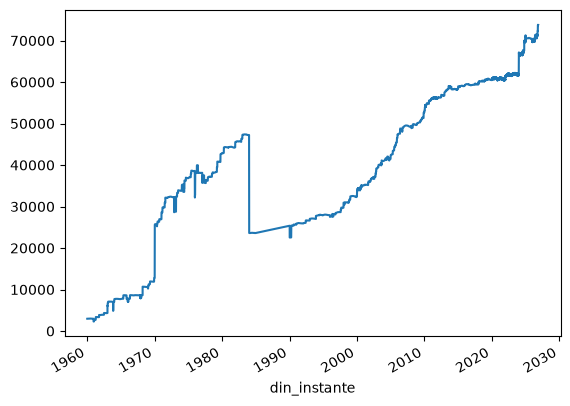

In [15]:
df['val_nivelmontante'].plot()